# Analytical SQL with DuckDB

PostgreSQL is built for **transactions**: many small reads and writes (OLTP). Analytics needs something else: scans and aggregations over millions of rows (OLAP). **DuckDB** is an in-process analytical database: no server, one `pip install`, SQL directly on Parquet, CSV and pandas DataFrames, and a **columnar**, **vectorised** engine that uses all CPU cores.

**After this lesson you can:**

1. Explain row stores vs column stores.
2. Query files, DataFrames and other databases with DuckDB.
3. Use Parquet and measure its benefits.
4. Compare DuckDB, SQLite and pandas on the same aggregation.

In [1]:
import sys
import tempfile
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets

WORK = Path(tempfile.mkdtemp())
print("DuckDB", duckdb.__version__)

DuckDB 1.5.6


## 1. Row Store vs Column Store

| | Row store (PostgreSQL, SQLite) | Column store (DuckDB, BigQuery, Snowflake) |
| :--- | :--- | :--- |
| storage | all columns of a row together | all values of a column together |
| best for | read/write one row: "show order 42" | aggregate a few columns over many rows |
| compression | modest | high (similar values are adjacent) |
| typical use | applications (OLTP) | analytics, dashboards, data science (OLAP) |

A query such as `SELECT avg(price) FROM sales` reads only the `price` column in a column store, but every whole row in a row store.

## 2. DuckDB on Real Data: Attach the Chinook SQLite File

DuckDB can attach a SQLite (or PostgreSQL, MySQL) database and query it with its own engine.

In [2]:
con = duckdb.connect()
con.execute(f"ATTACH '{datasets.fetch('chinook.sqlite')}' AS chinook (TYPE sqlite, READ_ONLY)")
con.sql("SHOW ALL TABLES").df()[["database", "name"]].head(12)

,database,name
0,chinook,Album
1,chinook,Artist
2,chinook,Customer
3,chinook,Employee
4,chinook,Genre
5,chinook,Invoice
6,chinook,InvoiceLine
7,chinook,MediaType
8,chinook,Playlist
9,chinook,PlaylistTrack


In [3]:
con.sql("""
SELECT g.Name AS genre, count(*) AS tracks, round(avg(t.Milliseconds) / 60000, 2) AS avg_minutes,
       round(sum(il.UnitPrice * il.Quantity), 2) AS revenue
FROM chinook.Track t
JOIN chinook.Genre g USING (GenreId)
LEFT JOIN chinook.InvoiceLine il USING (TrackId)
GROUP BY ALL
ORDER BY revenue DESC NULLS LAST
LIMIT 6
""").df()

,genre,tracks,avg_minutes,revenue
0,Rock,1387,4.72,826.65
1,Latin,625,3.88,382.14
2,Metal,407,5.15,261.36
3,Alternative & Punk,373,3.88,241.56
4,TV Shows,97,35.60,93.53
5,Jazz,142,4.82,79.20


`GROUP BY ALL` is a DuckDB convenience: it groups by every non-aggregated column. DuckDB also supports `SELECT * EXCLUDE (col)`, `PIVOT`, and reading files with a path in the `FROM` clause.

## 3. Query Files and DataFrames Directly

DuckDB queries a pandas DataFrame by its variable name, and a Parquet or CSV file by its path, without loading them into a database first. The cell builds a synthetic sales table with 5 million rows and saves it as CSV and Parquet.

In [4]:
rng = np.random.default_rng(0)
n = 5_000_000
sales = pd.DataFrame({
    "order_id": np.arange(n),
    "store": rng.choice([f"S{i:03d}" for i in range(200)], n),
    "category": rng.choice(["books", "music", "games", "video", "toys"], n, p=[.3, .25, .2, .15, .1]),
    "day": pd.to_datetime("2024-01-01") + pd.to_timedelta(rng.integers(0, 366, n), unit="D"),
    "amount": rng.gamma(2.0, 15.0, n).round(2),
})
csv_path, parquet_path = WORK / "sales.csv", WORK / "sales.parquet"
t = time.perf_counter(); sales.to_csv(csv_path, index=False); t_csv = time.perf_counter() - t
t = time.perf_counter(); sales.to_parquet(parquet_path, index=False); t_pq = time.perf_counter() - t
print(f"CSV     {csv_path.stat().st_size / 1e6:7.1f} MB, written in {t_csv:.1f} s")
print(f"Parquet {parquet_path.stat().st_size / 1e6:7.1f} MB, written in {t_pq:.1f} s")

con.sql("SELECT category, count(*) AS orders, round(sum(amount)) AS revenue FROM sales GROUP BY ALL ORDER BY revenue DESC").df()

CSV       177.2 MB, written in 7.9 s
Parquet    43.1 MB, written in 2.0 s


,category,orders,revenue
0,books,1501255,45008199.0
1,music,1250728,37561708.0
2,games,1000019,30017554.0
3,video,749272,22470944.0
4,toys,498726,14975511.0


**Parquet** is a columnar file format: it stores each column separately, compressed, with min/max statistics per block. It is the standard file format of data lakes (M12).

## 4. Benchmark: the Same Question in Four Ways

**Question:** revenue per category and month. The cell measures:

1. pandas `groupby` on the DataFrame in memory,
2. SQLite (a row store) on the same data,
3. DuckDB on the CSV file,
4. DuckDB on the Parquet file.

In [5]:
import sqlite3

query = """SELECT category, date_trunc('month', day) AS month, sum(amount) AS revenue
           FROM {src} GROUP BY ALL"""
sqlite_path = WORK / "sales.sqlite"
lite = sqlite3.connect(sqlite_path)
sales.assign(day=sales["day"].dt.strftime("%Y-%m-%d")).to_sql("sales", lite, index=False, chunksize=200_000)

def bench(fn, repeat=3):
    best = float("inf")
    for _ in range(repeat):
        t = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t)
    return best

timings = {
    "pandas groupby": bench(lambda: sales.groupby(["category", sales["day"].dt.to_period("M")])["amount"].sum()),
    "SQLite": bench(lambda: lite.execute("SELECT category, substr(day, 1, 7), sum(amount) FROM sales GROUP BY 1, 2").fetchall(), 1),
    "DuckDB on CSV": bench(lambda: con.sql(query.format(src=f"'{csv_path}'")).fetchall()),
    "DuckDB on Parquet": bench(lambda: con.sql(query.format(src=f"'{parquet_path}'")).fetchall()),
}
for name, t in timings.items():
    print(f"{name:<18} {t * 1000:9.0f} ms")

pandas groupby           329 ms
SQLite                  4977 ms
DuckDB on CSV            456 ms
DuckDB on Parquet        112 ms


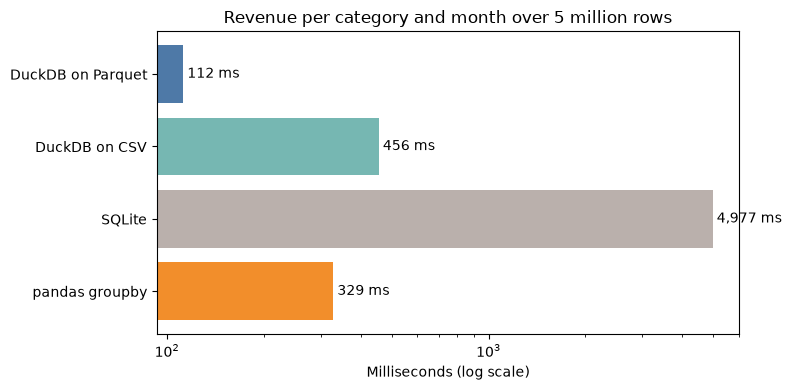

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
names = list(timings)
ax.barh(names, [timings[k] * 1000 for k in names], color=["#F28E2B", "#BAB0AC", "#76B7B2", "#4E79A7"])
for i, k in enumerate(names):
    ax.text(timings[k] * 1000, i, f" {timings[k] * 1000:,.0f} ms", va="center")
ax.set(xscale="log", title="Revenue per category and month over 5 million rows", xlabel="Milliseconds (log scale)")
plt.tight_layout()
plt.show()

DuckDB on Parquet reads only the three columns it needs, in compressed form, with all CPU cores. SQLite must read every full row with one core. DuckDB on CSV must parse text, so it is slower than on Parquet but still fast. Exact numbers depend on your machine (and on the disk: this course runs on a Windows drive under WSL).

## 5. Export Results

DuckDB writes query results to Parquet, CSV or JSON with `COPY ... TO`, and can write **partitioned** folders (one sub-folder per value), the layout that data lakes use.

In [7]:
out = WORK / "lake"
con.sql(f"COPY (SELECT *, year(day) AS year, month(day) AS month FROM '{parquet_path}') "
        f"TO '{out}' (FORMAT parquet, PARTITION_BY (year, month), OVERWRITE_OR_IGNORE)")
files = sorted(out.rglob("*.parquet"))
print(f"{len(files)} partition files, e.g. {files[0].relative_to(out)}")
print(con.sql(f"SELECT count(*) AS rows_in_march FROM read_parquet('{out}/*/*/*.parquet', hive_partitioning = true) "
              f"WHERE month = 3").df())

12 partition files, e.g. year=2024/month=1/data_0.parquet
   rows_in_march
0         424041


The last query filters on `month = 3`: DuckDB reads only the files in the `month=3` folder (**partition pruning**).

*Insight: Use PostgreSQL for the application and DuckDB (or a cloud warehouse) for analysis. For local data science, DuckDB on Parquet often replaces a database server entirely: one file, SQL, and enough speed for hundreds of millions of rows on a laptop.*

## Real-World Use Case or Analogy

A row store is like a **filing cabinet with one folder per customer**: perfect to pull out one customer's file, slow to add up one number from every folder. A column store is like a **ledger with one page per field**: to sum all amounts, you read one page.

Data teams use DuckDB to explore Parquet exports from the data lake on a laptop, to run tests for dbt models, and inside data apps. The same columnar ideas power cloud warehouses such as BigQuery, Snowflake and Redshift (Lesson 19).